# 01 · Preprocessing — Raghavan 2021 PDAC (malignant compartment)

Isolate malignant cells, restrict to the PDAC disease call, threshold thin samples, integrate
patients (Harmony), embed, remove detached islands, split the manifold into its transcriptional
compartments, and fix a house orientation. Raghavan et al. (2021, *Cell*) profiled metastatic
PDAC biopsies by Seq-Well and defined the **classical ↔ basal-like** malignant plasticity axis
plus an intermediate co-expresser state. Whether the *embryonic* gastrulation / somitogenesis /
neural-crest axis is confined to one lobe or spans the manifold is **derived in 02 from the
signature geography**, not assumed here, so all compartments are carried forward. Every tunable
choice is *derived from this dataset*, not inherited. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>-4
name = os.path.basename(os.getcwd())                     # output dataset dir (carries -4 suffix)
ds   = name[:-2] if name.endswith('-4') else name        # dataset stem for raw input / titles
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # Category partition
pth  = os.path.join(*([os.pardir]*4))                    # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + ds)                          # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)    # h5ads (-4)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', ds, '| output dir:', name, '| category:', cat)

dataset: Raghavan2021_Pancreas | output dir: Raghavan2021_Pancreas-4 | category: Pancreas


### Load malignant compartment, restrict to PDAC
The loader exposes the publication's per-cell `cell_type`; the malignancy call is `celltype ==
'Malignant'`, taken directly (per protocol: use the publication's calls). Raghavan's biopsy
cohort also contains one **pancreatic neuroendocrine tumour (PANET)** patient (PANFR0580, 662
malignant cells) — a *distinct malignancy* from PDAC. Mixing a neuroendocrine tumour into a
ductal-adenocarcinoma developmental analysis would inject a disease-driven island, so we restrict
to the dataset's disease of record (`disease == 'PDAC'`), matching the summary-CSV Disease field.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant (all disease):', adata.shape, '| disease:', adata.obs['disease'].value_counts().to_dict())
adata = adata[adata.obs['disease'] == 'PDAC'].copy()
print('PDAC malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Raghavan2021_Pancreas
Done.
full atlas: (24412, 16814)
malignant (all disease): (7904, 16814) | disease: {'PDAC': 7242, 'PANET': 662}
PDAC malignant: (7242, 16814) | samples: 22
expression: X max 7.61 (log1p of normalize_total UMI counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Look for the largest **multiplicative** cliff in the sorted per-sample counts (the natural
separatrix between tumour-bearing samples and spillover). Here the largest ratio (2.67) sits at
the *bottom* of the distribution (120 → 45), i.e. two very thin samples (45, 29 cells) fall away
from a body of samples ≥120. Cutting at the geometric mean of that gap coincides with the
protocol's ≥100-cell floor, so we keep the 20 samples clearing 100 cells.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]; gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}) at rank {gap}')
FLOOR = 100
if gap == 0:
    print(f'gap at top of distribution (degenerate) -> fall back to >= {FLOOR}-cell floor'); thresh = FLOOR
else:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'derived threshold (geometric mean across gap) = {thresh}')
thresh = max(thresh, FLOOR)
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'threshold = {thresh}; kept {len(keep)}/{len(n)} samples (min kept = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [1053  674  612  574  555  516  390  376  322  260  250  237  229  208
  197  164  159  143  129  120   45   29]
largest multiplicative gap: 120 -> 45 (ratio 2.67) at rank 19
derived threshold (geometric mean across gap) = 73
threshold = 100; kept 20/22 samples (min kept = 120) -> 7168 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing): we take the
theta past which mixing plateaus. PDAC malignant cells are strongly patient-specific (distinct
CNVs / classical-basal balance); the pre-Harmony fraction is very high (~0.94) and collapses to
~0.26 by theta=2, plateauing thereafter, so theta=5 is chosen (past the plateau, not so strong as
to over-smooth). PC count (20) and UMAP spread (1.3) follow the 10x/Seq-Well precedents (Steele /
Kürten / Sun, comparable cell counts).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 5
print('selected theta =', theta, '(mixing plateaus by theta=2; theta=5 past the plateau)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1308 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1308
same-sample neighbour fraction | pre-Harmony 0.938 | sweep {2: 0.267, 5: 0.258, 10: 0.264}
selected theta = 5 (mixing plateaus by theta=2; theta=5 past the plateau)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and keep the largest
connected component — stripping physically detached specks while preserving the continuous arm
termini. Here the manifold is already one connected mass, so nothing is removed (reported explicitly).

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy(); print('after island removal:', adata.shape[0], 'cells')

removed 0 cells in 0 detached islands
after island removal: 7168 cells


### Compartment split + labelling (data-driven, marker-based)
Low-resolution Leiden (res=0.15) recovers the manifold's lobes. We label them *by biology*: a lobe
whose **cycling fraction** greatly exceeds the overall rate is a **Cycling** proliferation state;
the remaining lobes are labelled from Moffitt classical/basal signatures (Moffitt et al. 2015 — the
same axis Raghavan uses) as **Classical-ductal** (higher classical score) vs **Basal-like**. Three
lobes are recovered here: a classical-ductal body, a basal-leaning body, and a small (~11%) cycling
lobe (82% cycling vs 17% overall). Whether the trajectory is scoped to one lobe or spans the whole
manifold — and whether cycling confounds the developmental axis — is decided in **02** from the
signature geography and an explicit cell-cycle confound test, not assumed here; all lobes are
carried forward.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
overall_cyc = adata.obs['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % overall_cyc)
cyc_lobe = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('cycling fraction per lobe:', cyc_lobe.round(3).to_dict())
classical = ['GATA6','TFF1','TFF2','LGALS4','CEACAM6','CEACAM5','TSPAN8','AGR2','CLRN3','CDH17']
basal = ['KRT17','KRT15','KRT6A','KRT5','KRT7','KRT14','TP63','S100A2','SPRR3','SPRR1B','LY6D','FAM83A','SLC2A1']
for nm,gs in [('classical',classical),('basal',basal)]:
    g = [x for x in gs if x in adata.var_names]
    sc.tl.score_genes(adata, g, score_name=nm+'_score', random_state=SEED)
    print(f'{nm}: {len(g)}/{len(gs)} genes | per-lobe mean',
          adata.obs.groupby('lobe', observed=True)[nm+'_score'].mean().round(3).to_dict())
cyc_set = set(cyc_lobe.index[cyc_lobe > 3*overall_cyc])       # proliferation lobe(s)
cl = adata.obs.groupby('lobe', observed=True)['classical_score'].mean()
noncyc = [l for l in cl.index if l not in cyc_set]
cl_lobe = cl.loc[noncyc].idxmax()
lab_map = {}
for l in adata.obs['lobe'].cat.categories:
    if l in cyc_set: lab_map[l] = 'Cycling'
    elif l == cl_lobe: lab_map[l] = 'Classical-ductal'
    else: lab_map[l] = 'Basal-like'
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'1': 3790, '0': 2563, '2': 815}
overall cycling fraction: 0.166
cycling fraction per lobe: {'0': 0.088, '1': 0.078, '2': 0.822}
classical: 10/10 genes | per-lobe mean {'0': 0.188, '1': 0.33, '2': 0.098}
basal: 13/13 genes | per-lobe mean {'0': 0.06, '1': 0.06, '2': 0.136}
compartments: {'Classical-ductal': 3790, 'Basal-like': 2563, 'Cycling': 815}


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so all trajectory panels are
shown after a single **rigid rotation** to the house horizontal layout (distance-preserving — *not*
a re-embedding, which would fold an anisotropic strip). The orientation is derived **once here**,
stored as `X_umap_lin`, and re-used unchanged by 02/03/04. Two ingredients: (i) the rotation angle
= the manifold's **axis of maximal variance**; (ii) the sign puts the **developmental origin on the
left** — set directly from the developmental-module geography (gastrulation/somitogenesis-high,
neural-crest-low pole on the left), scored here against the shared union pool solely to orient the
layout; 02 re-scores them canonically for the trajectory.

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = S[:,0] + S[:,1] - S[:,2]     # Gast/pSom-high & Crest-low = developmental origin

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'Gast/pSom-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.09
house orientation: rigid rotation +151.8deg (distances preserved), Gast/pSom-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made on the
regenerated embedding itself plus a per-neighbourhood metric (iLISI), not a scalar alone; the
deliverable `samples.pdf` follows.

In [9]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component after island removal);')
print('both compartments contain multiple samples.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=5) 6.90 of 20 samples
20 samples share one continuous manifold (one connected component after island removal);
both compartments contain multiple samples.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


### Save processed data

In [10]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (7168, 16763)


### Sample-integration figure (deliverable)
House style (`figsize=(3.5,1.5)` horizontal strip, `size=30`); colour = sample. Intermixing across
the strip is the Gate-1 batch-integration evidence, shown on the house orientation (`X_umap_lin`)
so this panel shares one orientation with 02/03/04.

saved samples.pdf | cells: 7168


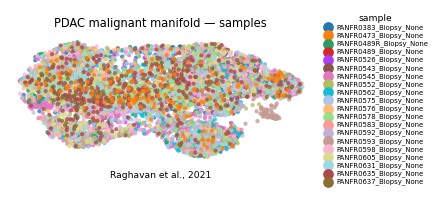

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.2, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('PDAC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])